In [1]:
import scipy
import numpy as np

from particle_filter.models.noise import GaussianNoise
from particle_filter.models.transition import GeneralTransitionModel
from particle_filter.models.observation import GeneralObservationModel

from particle_filter.plots.plot_results import plot_results

from particle_filter.performance_metrics import RMSE, Interval_cover, RMSE_time

En este notebook se aplica el filtro de partículas a modelos no aditivos.

### Caso 1: ruido gaussiano modelos no aditivos

El primer modelo (unidimesional) incorpora ruido gaussiano dentro de las funciones de transición y observación.

- Ecuación de transición:

$$
x_t = 0.5\cdot x_{t-1} + 25 \frac{x_{t-1}}{1+x_{t-1}^2}+8\cdot \cos(1.2)+\sigma \cdot x_{t-1}\cdot w_{t}
$$

con $\sigma = 0.5$, $w_t \sim \mathcal{N}(0, 0.5)$

- Ecuación de observación:

$$
y_t = x_{t} + 0.2 \cdot x_{t} \cdot v_t + \epsilon_t\;\;\;v_t \sim \mathcal{N}(0, 1.0), \;\epsilon_t \sim \mathcal{N}(0, 0.01)
$$

El ruido $\epsilon_t$ se incluye para evitar los casos en los que, cuando $x_{t-1}=0$, la observación es exactamente cero ($y_t=0$) y, por tanto se tendría $p(y_t \mid x_{t-1}=0)=1$. En estos casos, se tendría una distribución degenerada y no una normal.

Para poder utilizar el APF, es necesario definir una función (a la que se denominará $\textit{transition\_mean}$) para poder ser usada en el paso de la predicción. Para este caso, esta función equivale a la ecuación de tranición sin el sumando que contiene el ruido, es decir

$$
x_t = 0.5\cdot x_{t-1} + 25 \frac{x_{t-1}}{1+x_{t-1}^2}+8\cdot \cos(1.2)
$$

Por otro lado, para la ecuación de observación, se necesita una definición de la log-verosimilitud para comparar la observación con los estados estimados. Dado que el ruido es gaussiano, la observación $y_t$ condiconada al estado conocido $x_{t-1}$ se distribuirá como una gaussiana. Dados que los dos ruidos presentes en la ecuación son idependientes esta distribución es 

$$
y_t \mid x_t \sim \mathcal{N}(x_t, \;0.04\;x_{t-1}^2 + 0.01^2)
$$

In [2]:
sigma = 0.5

# Función de transicion
def f(x, w):

    return (
        0.5 * x
        + 25 * x /(1+ x**2)
        + 8*np.cos(1.2)
        + sigma*x*w
    )


def transition_mean(x):

    return (
        0.5 * x
        + 25 * x /(1+ x**2)
        + 8*np.cos(1.2)
    ) 


# Ruido de transicion
Q = np.diag([1.0])
# Modelo de transición
noise_transition = GaussianNoise(Q)
transition = GeneralTransitionModel(f, noise_transition, transition_mean)

In [3]:
# Función de observación
def h(x, v):

    return (
        x + 0.2 * x * v
    )


sigma0 = 0.01

def loglikelihood(y, x):

    # Desviación estandar condicional
    sig = np.sqrt(0.04 * x**2 + sigma0**2)

    # Log-verosimilitud total
    return scipy.stats.norm(
        loc=x,
        scale=sig
    ).logpdf(y).sum()


# Ruido de observación
R = np.array([0.5])

# Modelo de observación
noise_obs = GaussianNoise(R)
observation = GeneralObservationModel(h, noise_obs, loglikelihood)

In [4]:
from function_experiment import filter

n_simulations = 10

T = 100
N = 1000
x0 = np.array([1.0])

filter(n_simulations, T, N, x0, transition, observation, "results_exp1_4")

Simulacion 1 finalizada.
Simulacion 2 finalizada.
Simulacion 3 finalizada.
Simulacion 4 finalizada.
Simulacion 5 finalizada.
Simulacion 6 finalizada.
Simulacion 7 finalizada.
Simulacion 8 finalizada.
Simulacion 9 finalizada.
Simulacion 10 finalizada.


In [2]:
import pickle

with open("results_exp1_1.pkl", "rb") as file:
    results1 = pickle.load(file)

with open("results_exp1_2.pkl", "rb") as file:
    results2 = pickle.load(file)

with open("results_exp1_3.pkl", "rb") as file:
    results3 = pickle.load(file)

with open("results_exp1_4.pkl", "rb") as file:
    results4 = pickle.load(file)


In [3]:
from functions_statistics import get_statistics

n_simulations = 10
T_simul = 100
N_particles = 1000

results = [results1, results2, results3, results4]
parameters = [ (0.5, 1.0), (1.0, 1.0), (0.5, 0.5), (1.0, 0.5)] #parameters[0]=Q; parameters[1]=R

statistics_results_bpf = {}
statistics_results_apf = {}

for i, result in enumerate(results):

    statistics_results_bpf[parameters[i]], statistics_results_apf[parameters[i]] = \
        get_statistics(n_simulations, T_simul, N_particles, result)

In [4]:
for key, values in statistics_results_bpf.items():

    print("Bootstrap")
    print(f"Q: {key[0]}, R: {key[1]}")
    print(f"RMSE: {values["RMSE"]["mean"]} +/- {values["RMSE"]["std"]}")
    print(f"Loglikelihood: {values["Loglikelihood"]["mean"]} +/- {values["Loglikelihood"]["std"]}")
    print(f"IC: {values["IC"]["mean"]} +/- {values["IC"]["std"]}")
    print("")
    

Bootstrap
Q: 0.5, R: 1.0
RMSE: 1.9892299910195725 +/- 0.29631316684557457
Loglikelihood: -293.1097903788456 +/- 12.996178475416441
IC: 93.0 +/- 2.309401076758503

Bootstrap
Q: 1.0, R: 1.0
RMSE: 2.27554165135962 +/- 0.31848650666526707
Loglikelihood: -313.52471004072856 +/- 13.434926928907986
IC: 93.0 +/- 2.788866755113585

Bootstrap
Q: 0.5, R: 0.5
RMSE: 1.4571334937272105 +/- 0.158248694082964
Loglikelihood: -289.90645275827535 +/- 23.015505657082677
IC: 98.0 +/- 1.4907119849998598

Bootstrap
Q: 1.0, R: 0.5
RMSE: 1.509615116243321 +/- 0.2720594413504907
Loglikelihood: -303.569385445247 +/- 16.547195595540042
IC: 97.0 +/- 1.1547005383792515



In [5]:
for key, values in statistics_results_apf.items():

    print("Auxiliary")
    print(f"Q: {key[0]}, R: {key[1]}")
    print(f"RMSE: {values["RMSE"]["mean"]} +/- {values["RMSE"]["std"]}")
    print(f"Loglikelihood: {values["Loglikelihood"]["mean"]} +/- {values["Loglikelihood"]["std"]}")
    print(f"IC: {values["IC"]["mean"]} +/- {values["IC"]["std"]}")
    print("")

Auxiliary
Q: 0.5, R: 1.0
RMSE: 1.9243458050928095 +/- 0.25033951772946034
Loglikelihood: -290.0658128959258 +/- 7.068319542899388
IC: 93.3 +/- 2.496664441476534

Auxiliary
Q: 1.0, R: 1.0
RMSE: 2.3498106109178587 +/- 0.2981119358189391
Loglikelihood: -325.67230051002537 +/- 12.757693490207965
IC: 92.3 +/- 2.3118054512532935

Auxiliary
Q: 0.5, R: 0.5
RMSE: 1.4374359050874372 +/- 0.15083023091964792
Loglikelihood: -284.8459803078926 +/- 10.804035945646211
IC: 97.7 +/- 1.636391694484477

Auxiliary
Q: 1.0, R: 0.5
RMSE: 1.7268859953094466 +/- 0.6535677970198759
Loglikelihood: -322.21412044592887 +/- 34.15266002602913
IC: 97.1 +/- 1.8529256146249726



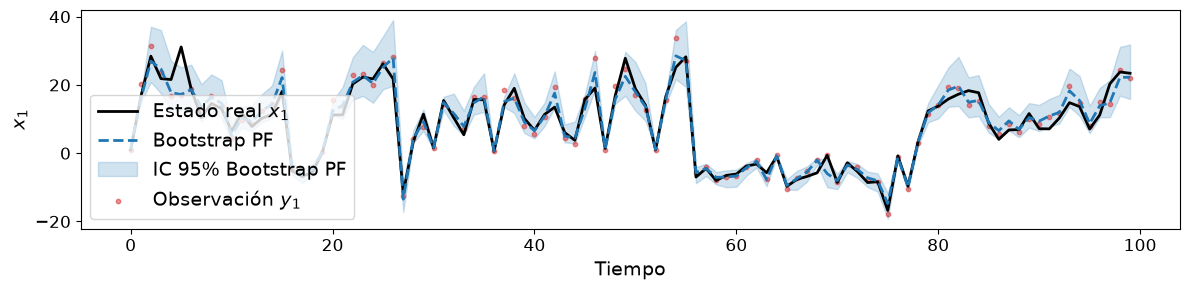

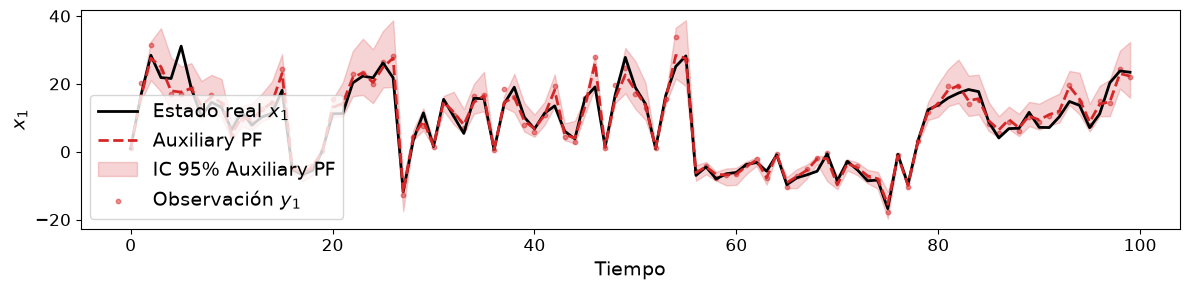

In [3]:
results_bpf = results2["Bootstrap"]
results_apf = results2["Auxiliary"]

i=2

estimates = {
    "Bootstrap PF": results_bpf[i]["results"]["estimates"],
    "Auxiliary PF": results_apf[i]["results"]["estimates"]
}

x_true = results_bpf[i]["x_true"]
y_obs = results_bpf[i]["y_obs"]

plot_results(x_true, y_obs, {"Bootstrap PF": results_bpf[i]["results"]["estimates"]}, 
             confidence_intervals={"Bootstrap PF": results_bpf[i]["results"]["intervals"]},
             x_title="Tiempo", plot_title="Evolución del estado estimado")

plot_results(x_true, y_obs, {"Auxiliary PF": results_apf[i]["results"]["estimates"]},
             confidence_intervals={"Auxiliary PF": results_apf[i]["results"]["intervals"]},
             x_title="Tiempo", plot_title="Evolución del estado estimado")

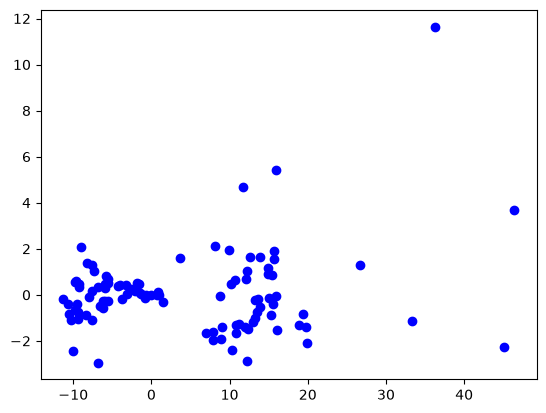

In [8]:
import matplotlib.pyplot as plt

i=0

estimates = results_bpf[i]["results"]["estimates"]
residuals = results_bpf[i]["x_true"] - results_bpf[i]["results"]["estimates"]

plt.scatter(estimates[:,0], residuals[:,0], color="blue")
#plt.scatter(estimates_2[:,0], residuals_2[:,0], color="orange")

plt.show()


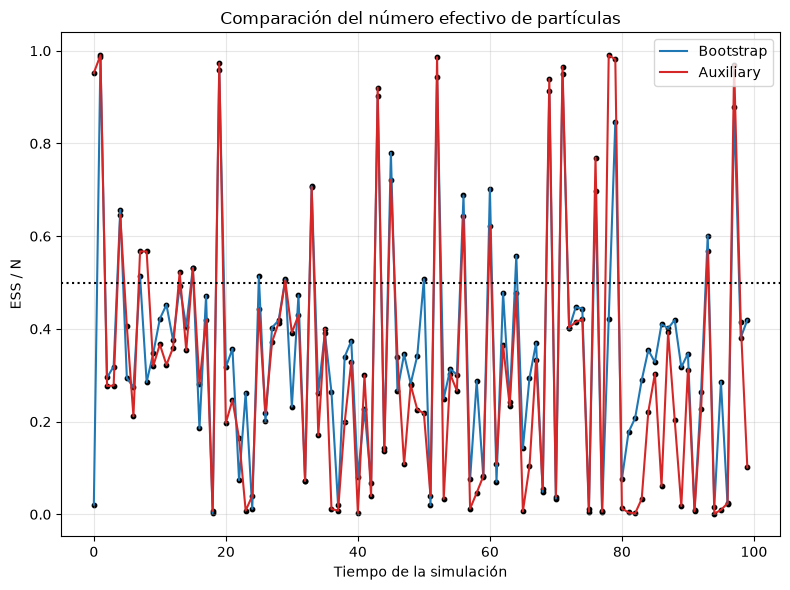

In [9]:
from particle_filter.plots.plot_EES import plot_ESS

plot_ESS(
    {"Bootstrap": results_bpf[i]["results"]["normalized_weights"],
     "Auxiliary": results_apf[i]["results"]["normalized_weights"]
     }
)


### Caso 2: ruido no gaussiano

En este segundo caso se implementa un ruido con una distribución t-Student

- Ecuación de transición:

$$
x_t = 0.8 \cdot x_{t-1} + (0.3 + 0.5\cdot x_{t-1})\cdot w_t
$$

con $w_t \sim t_3$

- Ecuación de observación:

$$
y_t = x_t + v_t
$$

con $v_t \sim t_3$

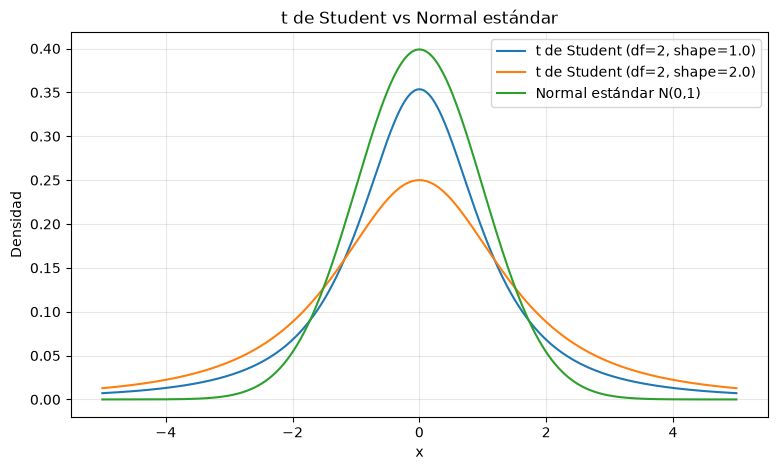

In [63]:
import matplotlib.pyplot as plt
from scipy.stats import multivariate_t, norm

# Valores de x
x = np.linspace(-5, 5, 1000)

# t de Student: df=2, loc=0, shape=0.5
t_dist1 = multivariate_t(loc=0, shape=1.0, df=2)
t_dist2 = multivariate_t(loc=0, shape=2.0, df=2)

# Normal estándar N(0,1)
normal_dist = norm(loc=0, scale=1)

# Densidades
pdf_t1 = t_dist1.pdf(x)
pdf_t2 = t_dist2.pdf(x)
pdf_normal = normal_dist.pdf(x)

# Gráfico
plt.figure(figsize=(9, 5))

plt.plot(x, pdf_t1, label='t de Student (df=2, shape=1.0)')
plt.plot(x, pdf_t2, label='t de Student (df=2, shape=2.0)')
plt.plot(x, pdf_normal, label='Normal estándar N(0,1)')

plt.xlabel('x')
plt.ylabel('Densidad')
plt.title('t de Student vs Normal estándar')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [39]:
from particle_filter.models.noise import StudentNoise

# Función de transicion
def f(x, w):

    return (
        0.8 * x + 
        (0.3 + 0.5 * x) * w
    )

def transition_mean(x):

    return (0.8 * x )

# Ruido de transicion
Q = np.diag([2.0])

# Modelo de transición
noise_transition = StudentNoise(Q, 2)
transition = GeneralTransitionModel(f, noise_transition, transition_mean)

In [40]:
from particle_filter.models.observation import AdditiveObservationModel

# Función de observación
def h(x):

    return x 

# Ruido de observación
R = np.array([2.0])

# Modelo de observación
noise_obs = StudentNoise(R, 2)
observation = AdditiveObservationModel(h, noise_obs)

In [41]:
from function_experiment import filter

n_simulations = 10

T = 100
N = 1000
x0 = np.array([1.0])

filter(n_simulations, T, N, x0, transition, observation, "results_exp2_8")

Simulacion 1 finalizada.
Simulacion 2 finalizada.
Simulacion 3 finalizada.
Simulacion 4 finalizada.
Simulacion 5 finalizada.
Simulacion 6 finalizada.
Simulacion 7 finalizada.
Simulacion 8 finalizada.
Simulacion 9 finalizada.
Simulacion 10 finalizada.


In [4]:
import pickle

with open("results_exp2_6.pkl", "rb") as file:
    results = pickle.load(file)

results_bpf = results["Bootstrap"]
results_apf = results["Auxiliary"]

In [3]:
n_simulations = 10

rmse_bpf = np.zeros(n_simulations)
rmse_apf = np.zeros(n_simulations)

loglikelihood_bpf = np.zeros(n_simulations)
loglikelihood_apf = np.zeros(n_simulations)

IC_bpf = np.zeros(n_simulations)
IC_apf = np.zeros(n_simulations)

for i in range(n_simulations):

    rmse_bpf[i] = RMSE(results_bpf[i]["x_true"], results_bpf[i]["results"]["estimates"])
    rmse_apf[i] = RMSE(results_apf[i]["x_true"], results_apf[i]["results"]["estimates"])

    if i==3:
        print(rmse_bpf[i])
        print(rmse_apf[i])

    loglikelihood_bpf[i] = results_bpf[i]["results"]["log_likelihood"]
    loglikelihood_apf[i] = results_apf[i]["results"]["log_likelihood"]

    IC_bpf[i] = Interval_cover(results_bpf[i]["x_true"], results_bpf[i]["results"]["intervals"])
    IC_apf[i] = Interval_cover(results_apf[i]["x_true"], results_apf[i]["results"]["intervals"])


print("RMSE")
print(f"Bootstrap Particle Filter: {np.mean(rmse_bpf)} +/- {np.std(rmse_bpf)}")
print(f"Auxiliary Particle Filter: {np.mean(rmse_apf)} +/- {np.std(rmse_apf)}")

print("Log-verosimilitud estimada")
print(f"Bootstrap Particle Filter: {np.mean(loglikelihood_bpf)} +/- {np.std(loglikelihood_bpf)}")
print(f"Auxiliary Particle Filter: {np.mean(loglikelihood_apf)} +/- {np.std(loglikelihood_apf)}")

print("Interval cover")
print(f"Bootstrap Particle Filter: {np.mean(IC_bpf)} +/- {np.std(IC_bpf)}")
print(f"Auxiliary Particle Filter: {np.mean(IC_apf)} +/- {np.std(IC_apf)}")

72.43516823878815
127.84313923574462
RMSE
Bootstrap Particle Filter: 8.875223266729884 +/- 21.215837214591854
Auxiliary Particle Filter: 14.283501135431626 +/- 37.860755015573346
Log-verosimilitud estimada
Bootstrap Particle Filter: -260.3659298159158 +/- 42.86004808793389
Auxiliary Particle Filter: -261.70026865590296 +/- 43.807177322905815
Interval cover
Bootstrap Particle Filter: 94.4 +/- 2.4576411454889016
Auxiliary Particle Filter: 94.3 +/- 2.6476404589747458


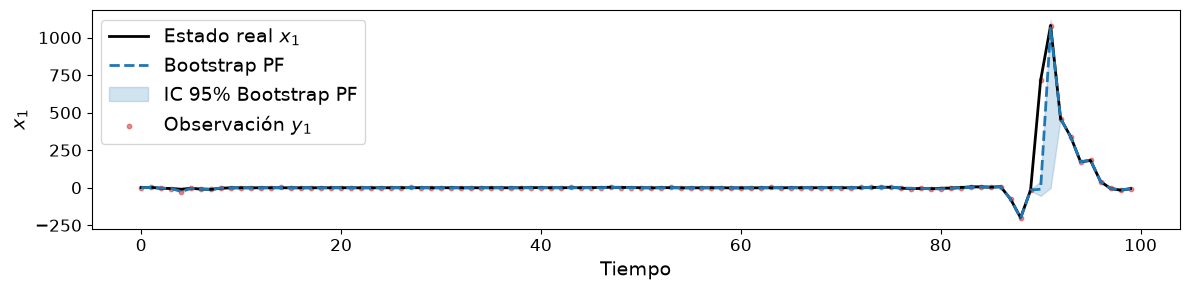

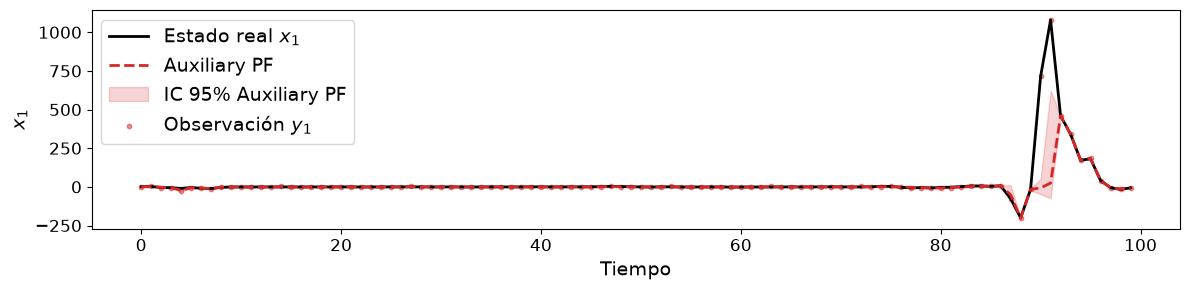

In [5]:
i=3

estimates = {
    "Bootstrap PF": results_bpf[i]["results"]["estimates"],
    "Auxiliary PF": results_apf[i]["results"]["estimates"]
}

x_true = results_bpf[i]["x_true"]
y_obs = results_bpf[i]["y_obs"]

plot_results(x_true, y_obs, {"Bootstrap PF": results_bpf[i]["results"]["estimates"]}, 
             confidence_intervals={"Bootstrap PF": results_bpf[i]["results"]["intervals"]},
             x_title="Tiempo", plot_title="Evolución del estado estimado")

plot_results(x_true, y_obs, {"Auxiliary PF": results_apf[i]["results"]["estimates"]},
             confidence_intervals={"Auxiliary PF": results_apf[i]["results"]["intervals"]},
             x_title="Tiempo", plot_title="Evolución del estado estimado")

In [10]:
print(RMSE(results_bpf[i]["x_true"][80:,:], results_bpf[i]["results"]["estimates"][80:,:]))
print(RMSE(results_apf[i]["x_true"][80:,:], results_apf[i]["results"]["estimates"][80:,:]))

161.92980401979395
285.8466497008007


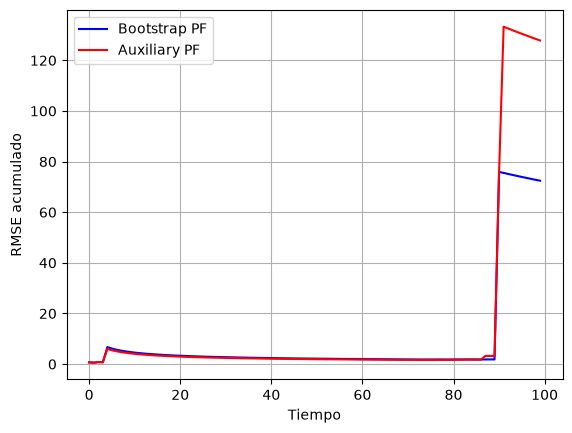

In [ ]:
import matplotlib.pyplot as plt

T = 100
i=3
_, rmse_acumulado_bpf = RMSE_time(results_bpf[i]["x_true"], results_bpf[i]["results"]["estimates"])
_, rmse_acumulado_apf = RMSE_time(results_apf[i]["x_true"], results_apf[i]["results"]["estimates"]) 

plt.plot(np.arange(T), rmse_acumulado_bpf, color = "blue", linestyle = "-", label="Bootstrap PF")
plt.plot(np.arange(T), rmse_acumulado_apf, color = "red", linestyle = "-", label="Auxiliary PF")

plt.xlabel("Tiempo")
plt.ylabel("RMSE acumulado")
#plt.title(f"RMSE acumulado en función del criterio de remuestreo (Q={q})")

plt.grid(True)
plt.legend()
plt.show()

### Caso 3: ruido multiplicativo en la observación

- Ecuación de transición:

$$
x_t = 0.9 \cdot x_{t-1} + w_t, \;\;\; w_t \sim \mathcal{N}(0, Q)
$$

con $Q=0.2$.

- Ecuación de observación:

$$
y_t = x_t + \lambda\;|x_t|\;v_t + \epsilon_t,\;\;\;v_t \sim \mathcal{N}(0 ,R)\; \epsilon_t \sim \mathcal{N}(0, R_0)
$$

con $R=0.5, \lambda=0.8$.

De esta última ecuación se obtiene la verosimilitud condicional. Dado que $v_t \sim \mathcal{N}(0, R)$, al multiplicarlo por $\lambda |x_t|$,

$$
\lambda\; |x_t|\;w_t \sim \mathcal{N}(0, \lambda^2\;|x_t|^2\; R)
$$

Además, como $\epsilon_t \sim \mathcal{N}(0, R_0)$ y los dos ruidos son independientes, la suma de dos variables normales independientes es normal:

$$
y_t \mid x_t \sim \mathcal{N}(x_t, \lambda^2\;|x_t|^2\;R + R_0)
$$

In [33]:
from particle_filter.models.transition import AdditiveTransitionModel

# Función de transicion
def f(x):

    return 0.9 * x

# Ruido de transicion
Q = np.diag([0.2])

# Modelo de transición
noise_transition = GaussianNoise(Q)
transition = AdditiveTransitionModel(f, noise_transition)

In [34]:
lamb = 0.8

# Función de observación
def h(x, v, epsilon):

    return x + lamb * np.abs(x) * v + epsilon


# Ruido de observación
R = np.array([1.0])
R0 = np.array([0.01])

def loglikelihood(y, x):

    sig = np.sqrt (lamb**2 * x**2 * R + R0)

    return scipy.stats.norm(
        loc=x,
        scale=sig
    ).logpdf(y).sum()

# Modelo de observación
noise_R = GaussianNoise(R)
noise_R0 = GaussianNoise(R0)
observation = GeneralObservationModel(h, noise=[noise_R, noise_R0], loglikelihood=loglikelihood)

In [35]:
from function_experiment import filter

n_simulations = 10

T = 100
N = 1000
x0 = np.array([1.0])

filter(n_simulations, T, N, x0, transition, observation, "results_exp3_3")

Simulacion 1 finalizada.
Simulacion 2 finalizada.
Simulacion 3 finalizada.
Simulacion 4 finalizada.
Simulacion 5 finalizada.
Simulacion 6 finalizada.
Simulacion 7 finalizada.
Simulacion 8 finalizada.
Simulacion 9 finalizada.
Simulacion 10 finalizada.


In [6]:
import pickle

with open("results_exp3_3.pkl", "rb") as file:
    results = pickle.load(file)

results_bpf = results["Bootstrap"]
results_apf = results["Auxiliary"]

In [37]:
n_simulations = 10

rmse_bpf = np.zeros(n_simulations)
rmse_apf = np.zeros(n_simulations)

loglikelihood_bpf = np.zeros(n_simulations)
loglikelihood_apf = np.zeros(n_simulations)

IC_bpf = np.zeros(n_simulations)
IC_apf = np.zeros(n_simulations)

for i in range(n_simulations):

    rmse_bpf[i] = RMSE(results_bpf[i]["x_true"], results_bpf[i]["results"]["estimates"])
    rmse_apf[i] = RMSE(results_apf[i]["x_true"], results_apf[i]["results"]["estimates"])

    loglikelihood_bpf[i] = results_bpf[i]["results"]["log_likelihood"]
    loglikelihood_apf[i] = results_apf[i]["results"]["log_likelihood"]

    IC_bpf[i] = Interval_cover(results_bpf[i]["x_true"], results_bpf[i]["results"]["intervals"])
    IC_apf[i] = Interval_cover(results_apf[i]["x_true"], results_apf[i]["results"]["intervals"])


print("RMSE")
print(f"Bootstrap Particle Filter: {np.mean(rmse_bpf)} +/- {np.std(rmse_bpf)}")
print(f"Auxiliary Particle Filter: {np.mean(rmse_apf)} +/- {np.std(rmse_apf)}")

print("Log-verosimilitud estimada")
print(f"Bootstrap Particle Filter: {np.mean(loglikelihood_bpf)} +/- {np.std(loglikelihood_bpf)}")
print(f"Auxiliary Particle Filter: {np.mean(loglikelihood_apf)} +/- {np.std(loglikelihood_apf)}")

print("Interval cover")
print(f"Bootstrap Particle Filter: {np.mean(IC_bpf)} +/- {np.std(IC_bpf)}")
print(f"Auxiliary Particle Filter: {np.mean(IC_apf)} +/- {np.std(IC_apf)}")

RMSE
Bootstrap Particle Filter: 0.4277051290771447 +/- 0.044796251776184154
Auxiliary Particle Filter: 0.44054586133564066 +/- 0.05165298595334473
Log-verosimilitud estimada
Bootstrap Particle Filter: -131.27667505295457 +/- 11.38805986368403
Auxiliary Particle Filter: -139.75851090208013 +/- 9.036497949598102
Interval cover
Bootstrap Particle Filter: 95.6 +/- 2.2891046284519194
Auxiliary Particle Filter: 94.9 +/- 1.9209372712298545


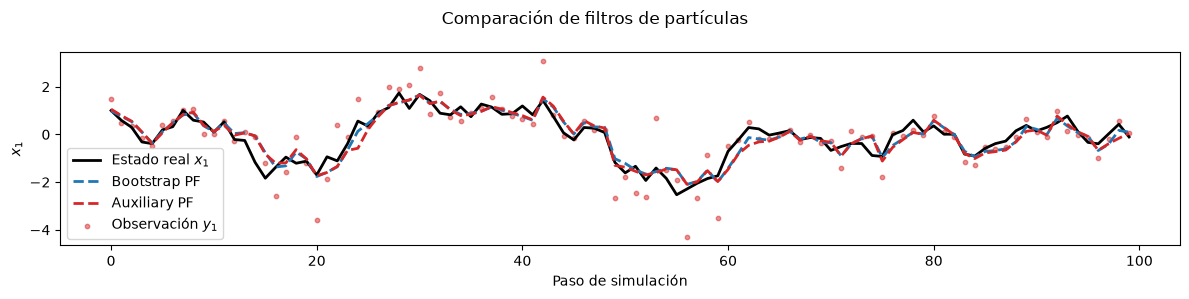

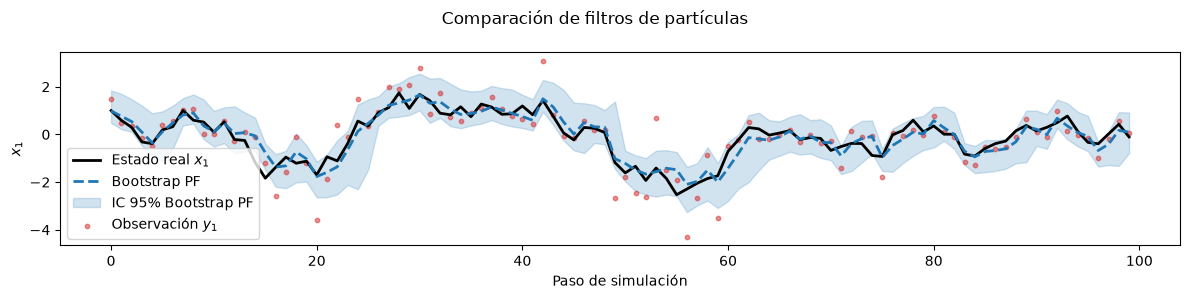

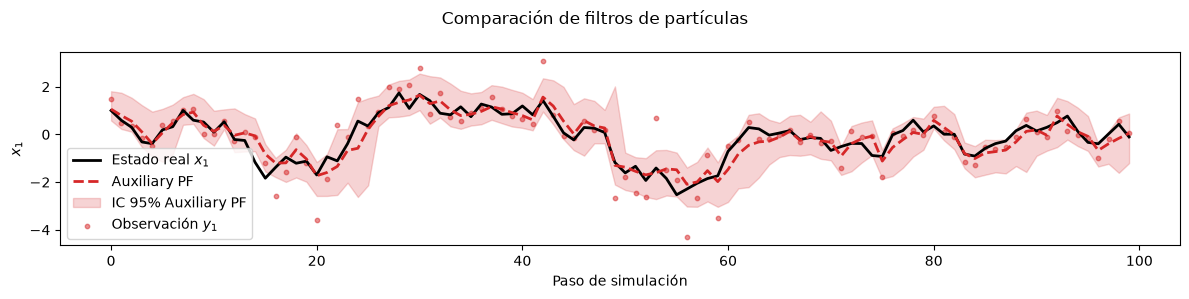

In [41]:
i=4

estimates = {
    "Bootstrap PF": results_bpf[i]["results"]["estimates"],
    "Auxiliary PF": results_apf[i]["results"]["estimates"]
}

x_true = results_bpf[i]["x_true"]
y_obs = results_bpf[i]["y_obs"]

plot_results(x_true, y_obs, estimates)

plot_results(x_true, y_obs, {"Bootstrap PF": results_bpf[i]["results"]["estimates"]}, 
             confidence_intervals={"Bootstrap PF": results_bpf[i]["results"]["intervals"]})

plot_results(x_true, y_obs, {"Auxiliary PF": results_apf[i]["results"]["estimates"]},
             confidence_intervals={"Auxiliary PF": results_apf[i]["results"]["intervals"]})

### Caso 4: ruido multiplicativo en la observación

- Ecuación de transición:

$$
x_t = 0.9 \cdot x_{t-1} + w_t, \;\;\; w_t \sim \mathcal{N}(0, Q)
$$

con $Q=0.2$.

- Ecuación de observación:

$$
y_t = x_t + \lambda\;|x_t|\;v_t ,\;\;\;v_t \sim t_3(0 ,R)\; 
$$

con $R=1.0, \lambda=0.8$.

De esta última ecuación se obtiene la verosimilitud condicional. Dado que $v_t \sim \mathcal{N}(0, R)$, al multiplicarlo por $\lambda |x_t|$,

$$
y_t \mid x_t \sim \mathcal{N}(x_t, \;\lambda^2\;|x_t|^2\;R)
$$

In [21]:
from particle_filter.models.transition import AdditiveTransitionModel

# Función de transicion
def f(x):

    return 0.9 * x

# Ruido de transicion
Q = np.diag([0.2])

# Modelo de transición
noise_transition = GaussianNoise(Q)
transition = AdditiveTransitionModel(f, noise_transition)

In [22]:
from particle_filter.models.noise import StudentNoise

lamb = 0.8

# Función de observación
def h(x, v):

    return x + lamb * np.abs(x) * v 

# Ruido de observación
R = np.array([1.0])

def loglikelihood(y, x):

    sig = np.sqrt (lamb**2 * x**2 * R)

    return scipy.stats.t(
        df=3,
        loc=x,
        scale=sig
    ).logpdf(y).sum()

# Modelo de observación
noise_R = StudentNoise(R, 3)
observation = GeneralObservationModel(h, noise=noise_R, loglikelihood=loglikelihood)

In [28]:
from function_experiment import filter

n_simulations = 10

T = 100
N = 1000
x0 = np.array([1.0])

filter(n_simulations, T, N, x0, transition, observation, "results_exp4_1")

Simulacion 1 finalizada.
Simulacion 2 finalizada.
Simulacion 3 finalizada.
Simulacion 4 finalizada.
Simulacion 5 finalizada.
Simulacion 6 finalizada.
Simulacion 7 finalizada.
Simulacion 8 finalizada.
Simulacion 9 finalizada.
Simulacion 10 finalizada.


In [11]:
with open("results_exp4_1.pkl", "rb") as file:
    res = pickle.load(file)

In [13]:
from functions_statistics import get_statistics

n_simulations = 10
T_simul = 100
N_particles = 1000

results = [res]

statistics_results_bpf = {}
statistics_results_apf = {}

for i, result in enumerate(results):

    statistics_results_bpf[i], statistics_results_apf[i] = \
        get_statistics(n_simulations, T_simul, N_particles, result)

In [14]:
i=0

print("RMSE")
print(f"Bootstrap Particle Filter: {statistics_results_bpf[i]["RMSE"]["mean"]} +/- {statistics_results_bpf[i]["RMSE"]["std"]}")
print(f"Auxiliary Particle Filter: {statistics_results_apf[i]["RMSE"]["mean"]} +/- {statistics_results_apf[i]["RMSE"]["std"]}")

print("Log-verosimilitud estimada")
print(f"Bootstrap Particle Filter: {statistics_results_bpf[i]["Loglikelihood"]["mean"]} +/- {statistics_results_bpf[i]["Loglikelihood"]["std"]}")
print(f"Auxiliary Particle Filter: {statistics_results_apf[i]["Loglikelihood"]["mean"]} +/- {statistics_results_apf[i]["Loglikelihood"]["std"]}")

print("Interval cover")
print(f"Bootstrap Particle Filter: {statistics_results_bpf[i]["IC"]["mean"]} +/- {statistics_results_bpf[i]["IC"]["std"]}")
print(f"Auxiliary Particle Filter:  {statistics_results_apf[i]["IC"]["mean"]} +/- {statistics_results_apf[i]["IC"]["std"]}")

RMSE
Bootstrap Particle Filter: 0.4553869297753256 +/- 0.07190677998741064
Auxiliary Particle Filter: 0.46128980569347605 +/- 0.06724500956850285
Log-verosimilitud estimada
Bootstrap Particle Filter: -140.11817690078038 +/- 13.726394097195769
Auxiliary Particle Filter: -142.7027438659474 +/- 13.276393909953764
Interval cover
Bootstrap Particle Filter: 95.4 +/- 1.955050439815357
Auxiliary Particle Filter:  95.4 +/- 2.1186998109427604


### Caso 5: ruido con distribución lognormal



En este caso el ruido de la ecuación de transición seguirá una distribución lognormal. Además este ruido será multiplicativo.

El modelo en espacio de estados será:

- Ecuación de transición:

$$
x_t = x_{t-1} \cdot w_t, \;\;\; w_t \sim Lognormal(\mu, \sigma^2)
$$

- Ecuación de observación:

$$
y_t = x_t + v_t, \;\;\; v_t \sim \mathcal{N}(0, R)
$$


Para poder aplicar el $Auxiliary\;Particle\;Filter$ se debe definir una función de predicción. En este caso, esta dada por

$$
\mathbb{E}[x_t] = \mathbb{E}[x_{t-1} \cdot w_t] = x_{t-1} \cdot e^{\mu + \frac{\sigma^2}{2}}
$$


In [15]:
from particle_filter.models.transition import GeneralTransitionModel
from particle_filter.models.noise import LognormalNoise

def f(x, w):

    return x * w


def transition_mean(x):

    return np.array (x * np.exp(0.125))


lognormal_noise = LognormalNoise(1, 0.5, 0.0)

transtion_model= GeneralTransitionModel(f, lognormal_noise, transition_mean)

In [16]:
from particle_filter.models.observation import AdditiveObservationModel
from particle_filter.models.noise import GaussianNoise

def h(x):

    return x

R = np.array([0.5])

observation_noise = GaussianNoise(R)
observation_model = AdditiveObservationModel(h, observation_noise)

In [17]:
from function_experiment import filter

n_simulations = 10

T = 100
N = 1000
x0 = np.array([1.0])

filter(n_simulations, T, N, x0, transtion_model, observation_model, "results_exp5_4")

Simulacion 1 finalizada.
Simulacion 2 finalizada.
Simulacion 3 finalizada.
Simulacion 4 finalizada.
Simulacion 5 finalizada.
Simulacion 6 finalizada.
Simulacion 7 finalizada.
Simulacion 8 finalizada.
Simulacion 9 finalizada.
Simulacion 10 finalizada.


In [26]:
import pickle

with open("results_exp5_4.pkl", "rb") as file:

    results = pickle.load(file)

results_bpf =results["Bootstrap"]
results_apf =results["Auxiliary"]

In [27]:
n_simulations = 10

rmse_bpf = np.zeros(n_simulations)
rmse_apf = np.zeros(n_simulations)

loglikelihood_bpf = np.zeros(n_simulations)
loglikelihood_apf = np.zeros(n_simulations)

IC_bpf = np.zeros(n_simulations)
IC_apf = np.zeros(n_simulations)

for i in range(n_simulations):

    rmse_bpf[i] = RMSE(results_bpf[i]["x_true"], results_bpf[i]["results"]["estimates"])
    rmse_apf[i] = RMSE(results_apf[i]["x_true"], results_apf[i]["results"]["estimates"])

    loglikelihood_bpf[i] = results_bpf[i]["results"]["log_likelihood"]
    loglikelihood_apf[i] = results_apf[i]["results"]["log_likelihood"]

    IC_bpf[i] = Interval_cover(results_bpf[i]["x_true"], results_bpf[i]["results"]["intervals"])
    IC_apf[i] = Interval_cover(results_apf[i]["x_true"], results_apf[i]["results"]["intervals"])


print("RMSE")
print(f"Bootstrap Particle Filter: {np.mean(rmse_bpf)} +/- {np.std(rmse_bpf)}")
print(f"Auxiliary Particle Filter: {np.mean(rmse_apf)} +/- {np.std(rmse_apf)}")

print("Log-verosimilitud estimada")
print(f"Bootstrap Particle Filter: {np.mean(loglikelihood_bpf)} +/- {np.std(loglikelihood_bpf)}")
print(f"Auxiliary Particle Filter: {np.mean(loglikelihood_apf)} +/- {np.std(loglikelihood_apf)}")

print("Interval cover")
print(f"Bootstrap Particle Filter: {np.mean(IC_bpf)} +/- {np.std(IC_bpf)}")
print(f"Auxiliary Particle Filter: {np.mean(IC_apf)} +/- {np.std(IC_apf)}")

RMSE
Bootstrap Particle Filter: 0.1 +/- 0.0
Auxiliary Particle Filter: 0.1 +/- 0.0
Log-verosimilitud estimada
Bootstrap Particle Filter: -105.76134157117465 +/- 6.451989580943842
Auxiliary Particle Filter: -105.82628734849814 +/- 6.497090452776759
Interval cover
Bootstrap Particle Filter: 99.0 +/- 0.0
Auxiliary Particle Filter: 99.0 +/- 0.0


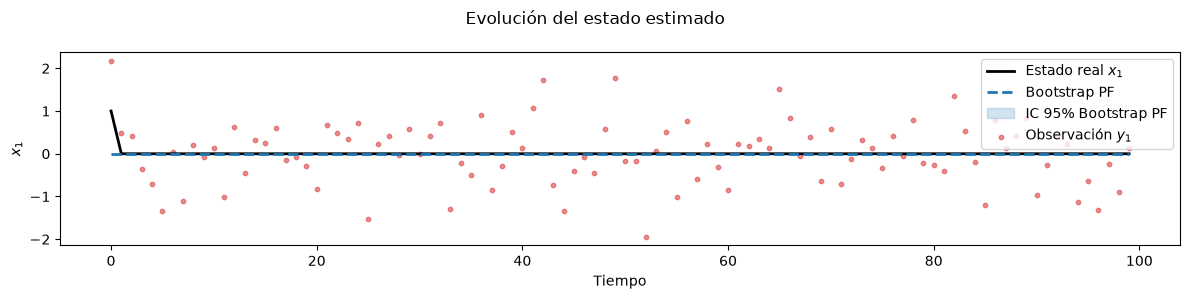

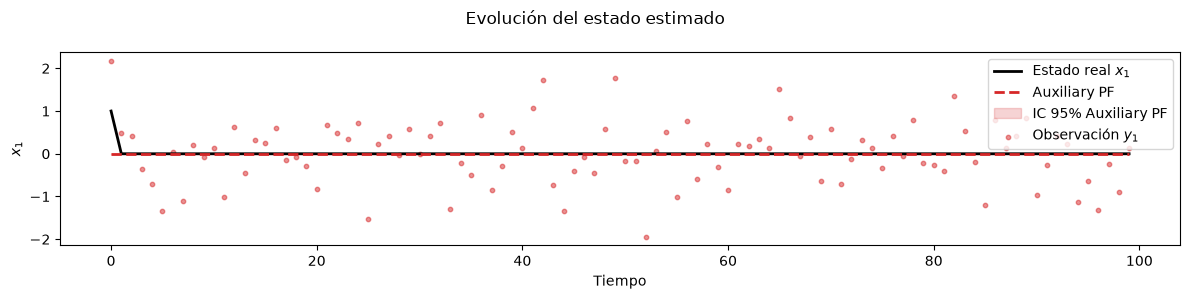

In [28]:
results_bpf = results["Bootstrap"]
results_apf = results["Auxiliary"]

i=9

estimates = {
    "Bootstrap PF": results_bpf[i]["results"]["estimates"],
    "Auxiliary PF": results_apf[i]["results"]["estimates"]
}

x_true = results_bpf[i]["x_true"]
y_obs = results_bpf[i]["y_obs"]


plot_results(x_true, y_obs, {"Bootstrap PF": results_bpf[i]["results"]["estimates"]}, 
             confidence_intervals={"Bootstrap PF": results_bpf[i]["results"]["intervals"]},
              x_title="Tiempo", plot_title="Evolución del estado estimado")

plot_results(x_true, y_obs, {"Auxiliary PF": results_apf[i]["results"]["estimates"]},
             confidence_intervals={"Auxiliary PF": results_apf[i]["results"]["intervals"]},
              x_title="Tiempo", plot_title="Evolución del estado estimado")

In [ ]:
print("RMSE")
print(f"RMSE Bootstrap: {RMSE(x_true, results_bpf[i]["results"]["estimates"])}")
print(f"RMSE Auxiliary: {RMSE(x_true, results_apf[i]["results"]["estimates"])}")
print("")
print("Log-verosimilitud estimada")
print(f"Log-verosimilitud Bootstrap: {results_bpf[i]["results"]["log_likelihood"]}")
print(f"Log-verosimilitud Auxiliary: {results_apf[i]["results"]["log_likelihood"]}")
print("")
print("Intervalo de cobertura")
print(f"IC Bootstrap: {Interval_cover(x_true, results_bpf[i]["results"]["intervals"])}")
print(f"IC Auxiliary: {Interval_cover(x_true, results_apf[i]["results"]["intervals"])}")

RMSE
RMSE Bootstrap: 24.10380498582072
RMSE Auxiliary: 8.206788068164899

Log-verosimilitud estimada
Log-verosimilitud Bootstrap: -58304.18222887232
Log-verosimilitud Auxiliary: -7328.521325328358

IC Bootstrap: 50.0
IC Auxiliary: 55.00000000000001


### Caso 6: Cambio de régimen (modelo multiplicativo)

- Ecuación de transición

$$
s_t \sim P(s_t \mid s_{t-1})\\
x_t = x_{t-1} + g_{s_t}(x_{t-1})\cdot w_t,\;\;\; w_t \sim \mathcal{N}(0, Q)
$$

$g_{s_t}$ será una de las posibles funciones y dependerá del valor de régimen $s_t$ en ese instante $t$. La transición $P(s_t \mid s_{t-1})$ estará dada por un proceso markoviano. Por ejemplo, para dos posibles regímenes:

$$
P(s_t \mid s_{t-1}) =
\begin{bmatrix}
s_{11} & s_{12} \\
s_{21} & s_{22}
\end{bmatrix}
$$

donde $s_{ij}$ indica la probabilidad de estando en el régimen $i$ pasar al régimen $j$.

- Ecuación de observación

$$
y_t = x_t + v_t, \;\;\; v_t \sim \mathcal{N}(0,R)
$$


Este ejemplo del modelo va a tener dos regímenes:

$$
g_1(x_{t-1}) = 0.1 + 0.05 \cdot x_{t-1} \\
g_2(x_{t-1}) = 0.8 + 0.2 \cdot x_{t-1}
$$

La matriz de transición entre regímenes está dada por:

$$
P(s_t \mid s_{t-1})=
\begin{bmatrix}
0.95 &0.05 \\
0.10 & 0.90
\end{bmatrix}
$$

Los ruidos del proceso son $Q=0.1, R=0.5$

In [68]:
from particle_filter.models.transition import RegimeTransitionModel
from particle_filter.models.noise import StudentNoise

# Primera función de transición
def f1(x, w):

    return np.array( x + (0.1 + 0.05 * x) * w)


def transition_mean1(x):

    return np.array( x + (0.1 + 0.05 * x))
    
# Primer modelo de transicion
Q1 = np.diag([1.0])

noise_transition_1 = GaussianNoise(Q1)
transition_1 = GeneralTransitionModel(f1, noise_transition_1, transition_mean1)

# Segunda función de transición
def f2(x, w):

    return np.array( x + (0.8 + 0.2 * x) * w)


def transition_mean2(x):

    return np.array( x + (0.8 + 0.2 * x))
    
# Primer modelo de transicion
Q2 = np.diag([2.0])

noise_transition_2 = StudentNoise(Q2, 2)
transition_2 = GeneralTransitionModel(f2, noise_transition_2, transition_mean2)

transition_models = [transition_1, transition_2]
regimes_transtion = [ [0.95, 0.05], [0.1, 0.9] ]

transition_model = RegimeTransitionModel(transition_models, regimes_transtion)

In [69]:
from particle_filter.models.observation import AdditiveObservationModel

# Funcion de observacion
def h(x):

    return np.array(x)

# Modelo de observacion
R = np.array([0.5])

noise_observation = GaussianNoise(R)
observation_model = AdditiveObservationModel(h, noise_observation)

In [70]:
from particle_filter.simulations import system_simulation_regime_model
from particle_filter.filtering_algorithms.particle_filter import BootstrapParticleFilterRegime, AuxiliaryParticleFilterRegime

T = 1000
N = 1000

regimen0 = np.random.choice(2)
x0 = np.array([1.0])

regimen_true, x_true, y_obs = system_simulation_regime_model(transition_model, observation_model, x0, regimen0, T)

results_bpf = []
results_apf = []

# Bootstrap PF
bpf = BootstrapParticleFilterRegime(
    N=N,
    transition_model=transition_model,
    observation_model=observation_model
)

bpf.initialize(mean=np.array([0.0]), cov=np.diag([1.0]))

est_bpf = bpf.run_filter(y_obs, resample_threshold=bpf.N/2)

results_bpf.append({
    "simulation": 0,
    "x_true": x_true,
    "y_obs": y_obs,
    "regimen_true": regimen_true,
    "results": est_bpf        
    })

# Auxiliary PF
apf = AuxiliaryParticleFilterRegime(
        N=N,
        transition_model=transition_model,
        observation_model=observation_model
    ) 

apf.initialize(mean=np.array([0.0]), cov=np.diag([1.0]))

est_apf = apf.run_filter(y_obs, resample_threshold=apf.N/2)

results_apf.append({
    "simulation": 0,
    "x_true": x_true,
    "y_obs": y_obs,
    "regimen_true": regimen_true,
    "results": est_apf        
    })

results = {
    "Bootstrap": results_bpf,
    "Auxiliary": results_apf
}

with open("results_exp6_13.pkl", "wb") as file:

    pickle.dump(results, file)

In [13]:
import pickle

with open("results_exp6_13.pkl", "rb") as file:

    results = pickle.load(file)

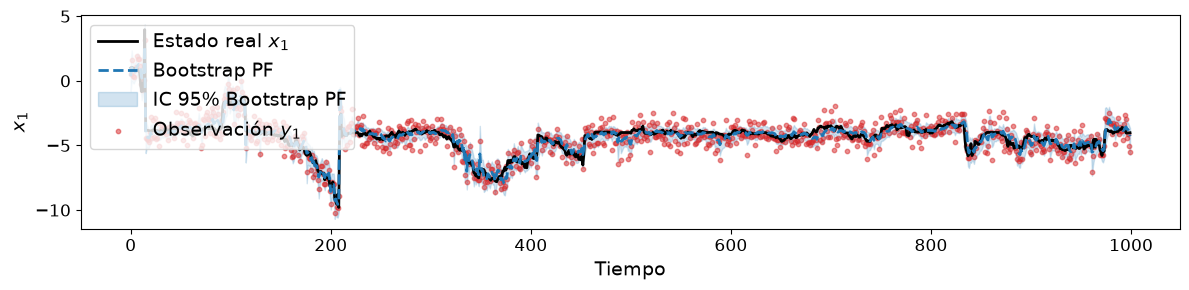

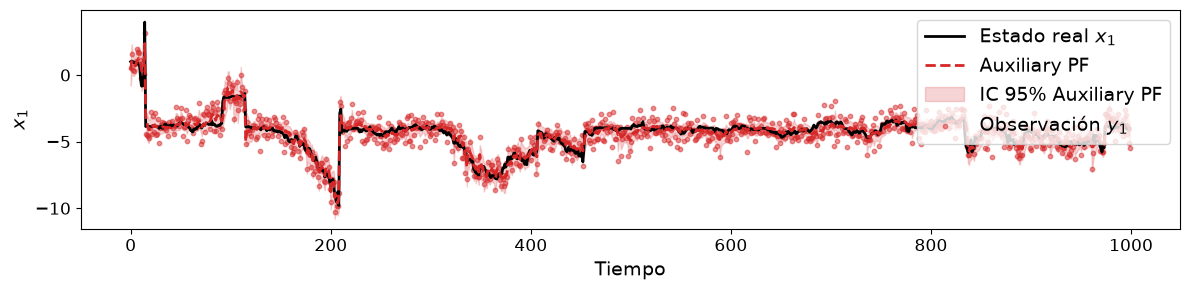

In [14]:
results_bpf = results["Bootstrap"]
results_apf = results["Auxiliary"]

i=0

estimates = {
    "Bootstrap PF": results_bpf[i]["results"]["estimates"],
    "Auxiliary PF": results_apf[i]["results"]["estimates"]
}

x_true = results_bpf[i]["x_true"]
y_obs = results_bpf[i]["y_obs"]


plot_results(x_true, y_obs, {"Bootstrap PF": results_bpf[i]["results"]["estimates"]},
             confidence_intervals={"Bootstrap PF": results_bpf[i]["results"]["intervals"]},
             x_title="Tiempo", plot_title="Evolución del estado estimado")

plot_results(x_true, y_obs, {"Auxiliary PF": results_apf[i]["results"]["estimates"]},
             confidence_intervals={"Auxiliary PF": results_apf[i]["results"]["intervals"]},
             x_title="Tiempo", plot_title="Evolución del estado estimado")

In [16]:
print("RMSE")
print(f"RMSE Bootstrap: {RMSE(x_true, results_bpf[i]["results"]["estimates"])}")
print(f"RMSE Auxiliary: {RMSE(x_true, results_apf[i]["results"]["estimates"])}")
print("")
print("Log-verosimilitud estimada")
print(f"Log-verosimilitud Bootstrap: {results_bpf[i]["results"]["log_likelihood"]}")
print(f"Log-verosimilitud Auxiliary: {results_apf[i]["results"]["log_likelihood"]}")
print("")
print("Intervalo de cobertura")
print(f"IC Bootstrap: {Interval_cover(x_true, results_bpf[i]["results"]["intervals"])}")
print(f"IC Auxiliary: {Interval_cover(x_true, results_apf[i]["results"]["intervals"])}")

RMSE
RMSE Bootstrap: 0.49259180612377307
RMSE Auxiliary: 0.5902959298646516

Log-verosimilitud estimada
Log-verosimilitud Bootstrap: -1625.3252518992506
Log-verosimilitud Auxiliary: -1943.3424652234942

Intervalo de cobertura
IC Bootstrap: 92.5
IC Auxiliary: 91.60000000000001


### Caso 7: Cambio de régimen

En este caso se tiene un modelo aditivo donde la ecuación de transición del sistema dependerá del régimen en el que se encuentre.

- Ecuación de transición

$$
s_t \sim P(s_t \mid s_{t-1})\\
x_t = a_{s_t} \cdot x_{t-1} + w_t, \;\;\; w_t \sim \mathcal{N}(0, Q)
$$

$a_{s_t}$ será uno de los posibles especificados y su valor dependerá del valor de régimen $s_t$ en ese instante $t$. La transición $P(s_t \mid s_{t-1}$ estará dada por un proceso markoviano. Por ejemplo, para dos posibles regímenes:

$$
P(s_t \mid s_{t-1}) =
\begin{bmatrix}
s_{11} & s_{12} \\
s_{21} & s_{22}
\end{bmatrix}
$$

donde $s_{ij}$ indica la probabilidad de estando en el régimen $i$ pasar al régimen $j$.

- Ecuación de observación

$$
y_t = x_t + v_t, \;\;\; v_t \sim \mathcal{N}(0,R)
$$

In [2]:
from particle_filter.models.transition import AdditiveTransitionModel

# Función de transición
def f(parameters):

    regimen, x = parameters

    # Cambio de regimen
    if regimen==1.0:
        regimen = np.random.choice([1.0, 2.0], p = [0.6, 0.4])

    else:
        regimen = np.random.choice([1.0, 2.0], p = [0.3, 0.7])

    # Transicion x
    if regimen == 1.0:
        x = 0.95 * x
    else:
        x = -0.40 * x

    return np.array([regimen, x])


# Modelo de transicion
Q = np.diag([0.0, 0.1])

noise_transition = GaussianNoise(Q)
transition = AdditiveTransitionModel(f, noise_transition)

In [23]:
from particle_filter.models.observation import AdditiveObservationModel

# Funcion de observacion
def h(parameters):

    _, x = parameters

    return x

# Modelo de observacion
R = np.array([0.5])

noise_observation = GaussianNoise(R)
observation = AdditiveObservationModel(h, noise_observation)

In [24]:
from particle_filter.simulations import system_simulation
from particle_filter.filtering_algorithms.particle_filter import BootstrapParticleFilter, AuxiliaryParticleFilter

T = 100
N = 1000

regimen0 = np.random.choice([1.0, 2.0])
x0 = np.array([regimen0, 1.0])

x_true, y_obs = system_simulation(transition, observation, x0, T)

results_bpf = []
results_apf = []

# Bootstrap PF
bpf = BootstrapParticleFilter(
        N=N,
        transition_model=transition,
        observation_model=observation
    ) 

regimen0 = np.random.choice([1.0, 2.0])
bpf.initialize(mean=np.array([regimen0, 0.0]), cov=np.diag([0.0, 1.0]))

est_bpf = bpf.run_filter(y_obs, resample_threshold=bpf.N/2)

results_bpf.append({
    "simulation": 0,
    "x_true": x_true,
    "y_obs": y_obs,
    "results": est_bpf        
    })

# Auxiliary PF
apf = AuxiliaryParticleFilter(
        N=N,
        transition_model=transition,
        observation_model=observation
    )

regimen0 = np.random.choice([1.0, 2.0])
apf.initialize(mean=np.array([regimen0, 0.0]), cov=np.diag([0.0, 1.0]))

est_apf = apf.run_filter(y_obs, resample_threshold=apf.N/2)

results_apf.append({
    "simulation": 0,
    "x_true": x_true,
    "y_obs": y_obs,
    "results": est_apf        
    })

results = {
    "Bootstrap": results_bpf,
    "Auxiliary": results_apf
}

with open("results_exp6_2.pkl", "wb") as file:

    pickle.dump(results, file)


In [25]:
with open("results_exp6_2.pkl", "rb") as file:

    results = pickle.load(file)

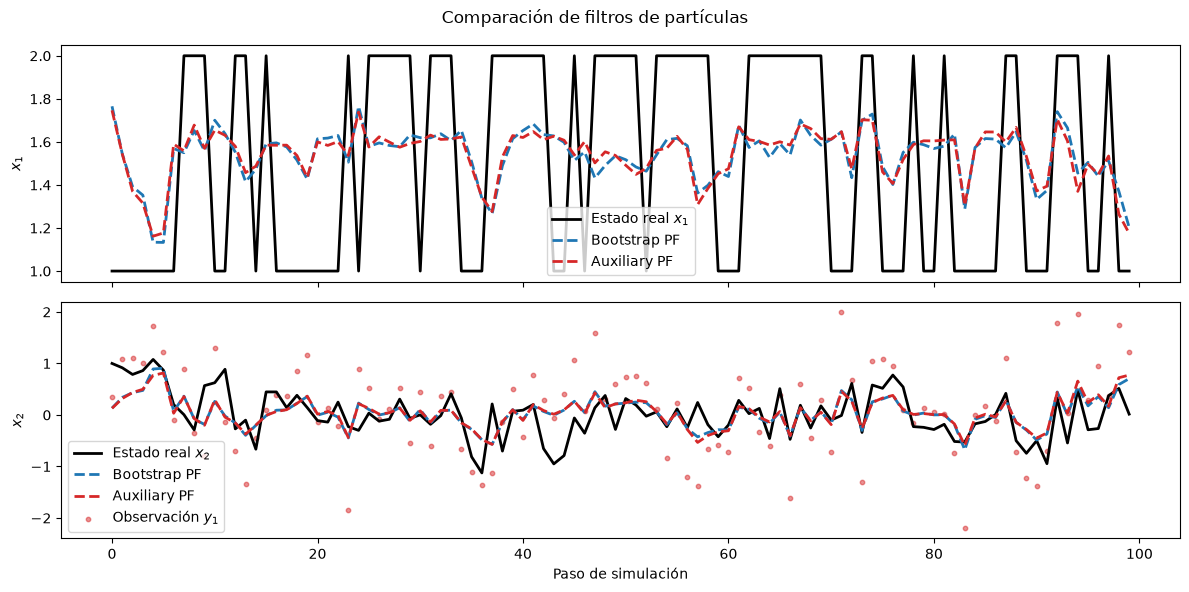

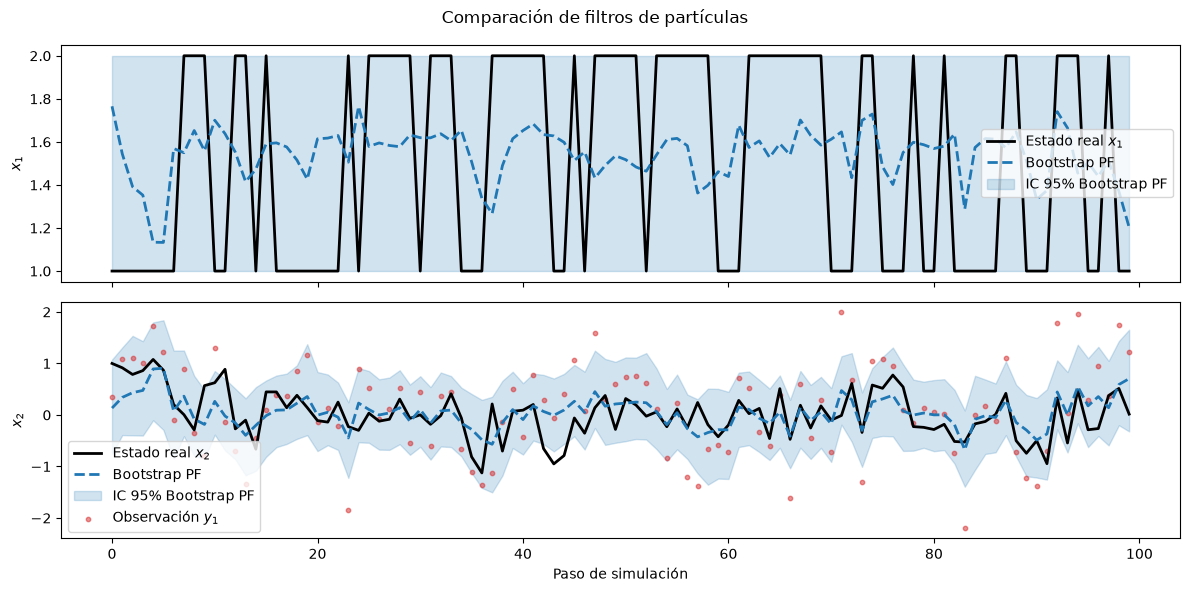

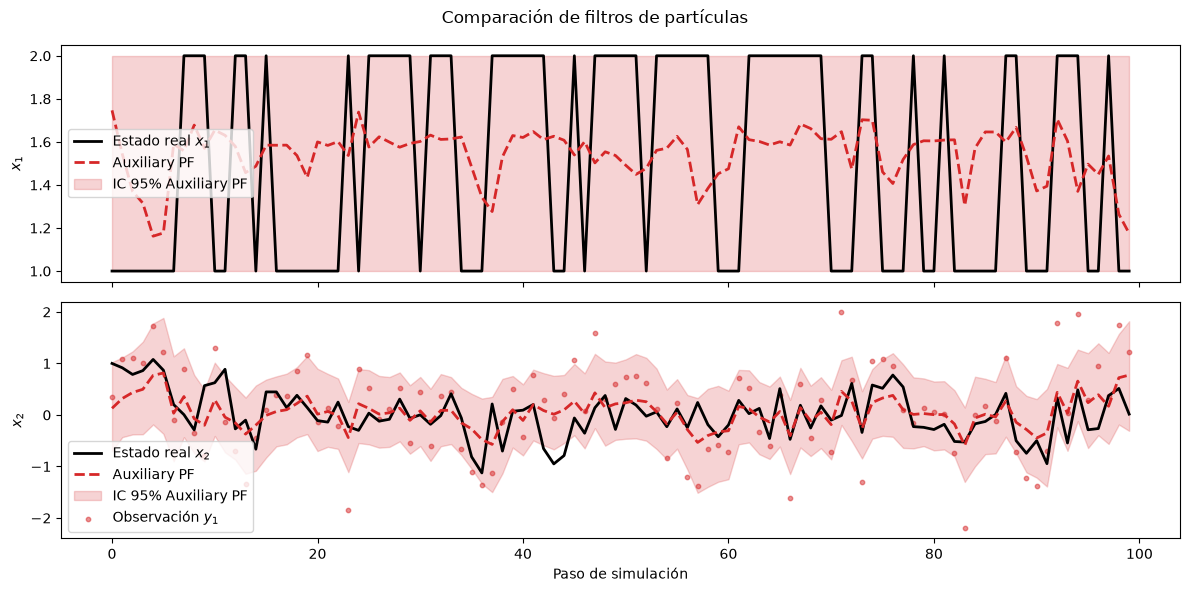

In [26]:
results_bpf = results["Bootstrap"]
results_apf = results["Auxiliary"]

i=0

estimates = {
    "Bootstrap PF": results_bpf[i]["results"]["estimates"],
    "Auxiliary PF": results_apf[i]["results"]["estimates"]
}

x_true = results_bpf[i]["x_true"]
y_obs = results_bpf[i]["y_obs"]

plot_results(x_true, y_obs, estimates, [1])

plot_results(x_true, y_obs, {"Bootstrap PF": results_bpf[i]["results"]["estimates"]}, observation_state_indices=[1],
             confidence_intervals={"Bootstrap PF": results_bpf[i]["results"]["intervals"]})

plot_results(x_true, y_obs, {"Auxiliary PF": results_apf[i]["results"]["estimates"]}, observation_state_indices=[1],
             confidence_intervals={"Auxiliary PF": results_apf[i]["results"]["intervals"]})

In [ ]:
print("RMSE")
print(f"RMSE Bootstrap (estado x): {RMSE(x_true[:,1], results_bpf[i]["results"]["estimates"][:,1])}")
print(f"RMSE Auxiliary (estado x): {RMSE(x_true[:,1], results_apf[i]["results"]["estimates"][:,1])}")
print("")
print("Log-verosimilitud estimada")
print(f"Log-verosimilitud Bootstrap: {results_bpf[i]["results"]["log_likelihood"]}")
print(f"Log-verosimilitud Auxiliary: {results_apf[i]["results"]["log_likelihood"]}")
print("")
print(f"IC Bootstrap: {Interval_cover(x_true, results_bpf[i]["results"]["intervals"])}")
print(f"IC Auxiliary: {Interval_cover(x_true, results_apf[i]["results"]["intervals"])}")

RMSE
RMSE Bootstrap: 0.3651358505355665
RMSE Auxiliary: 0.37514119805315627

Log-verosimilitud estimada
Log-verosimilitud Bootstrap: -127.94350621228892
Log-verosimilitud Auxiliary: -127.97656807734346

IC Bootstrap: 95.0
IC Auxiliary: 95.0
